In [1]:
import numpy as np
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [8]:
x,y = make_regression(
    n_samples = 1000,
    n_features=5,
    noise=20,
    random_state=42
)

In [27]:
np.random.seed(42)
n = 200

# Independent features
X1 = np.random.randn(n)
X2 = np.random.randn(n)

# Highly correlated features
X3 = X1 * 0.95 + np.random.normal(0, 0.05, n)
X4 = X2 * 0.95 + np.random.normal(0, 0.05, n)

# Another correlated feature
X5 = X1 * 0.8 + X2 * 0.2 + np.random.normal(0, 0.05, n)

# Target
y = (5 * X1 + 3 * X2 + np.random.normal(0, 1, n))


df = pd.DataFrame({
    "X1": X1,
    "X2": X2,
    "X3": X3,
    "X4": X4,
    "X5": X5,
    "Target": y
})

print(df.head(10))

         X1        X2        X3        X4        X5     Target
0  0.496714  0.357787  0.392157  0.377747  0.515843   4.956288
1 -0.138264  0.560785 -0.161320  0.486637 -0.024257   1.915666
2  0.647689  1.083051  0.615566  1.072379  0.739567   6.547227
3  1.523030  1.053802  1.449227  1.068894  1.406071  10.129619
4 -0.234153 -1.377669 -0.244949 -1.288114 -0.484581  -4.605552
5 -0.234137 -0.937825 -0.191288 -0.797094 -0.390333  -3.590675
6  1.579213  0.515035  1.446871  0.450594  1.377484  10.336363
7  0.767435  0.513786  0.721944  0.425864  0.692768   6.013703
8 -0.469474  0.515048 -0.439986  0.400359 -0.209782   0.247324
9  0.542560  3.852731  0.541154  3.734897  1.159864  13.735759


<Figure size 800x600 with 0 Axes>

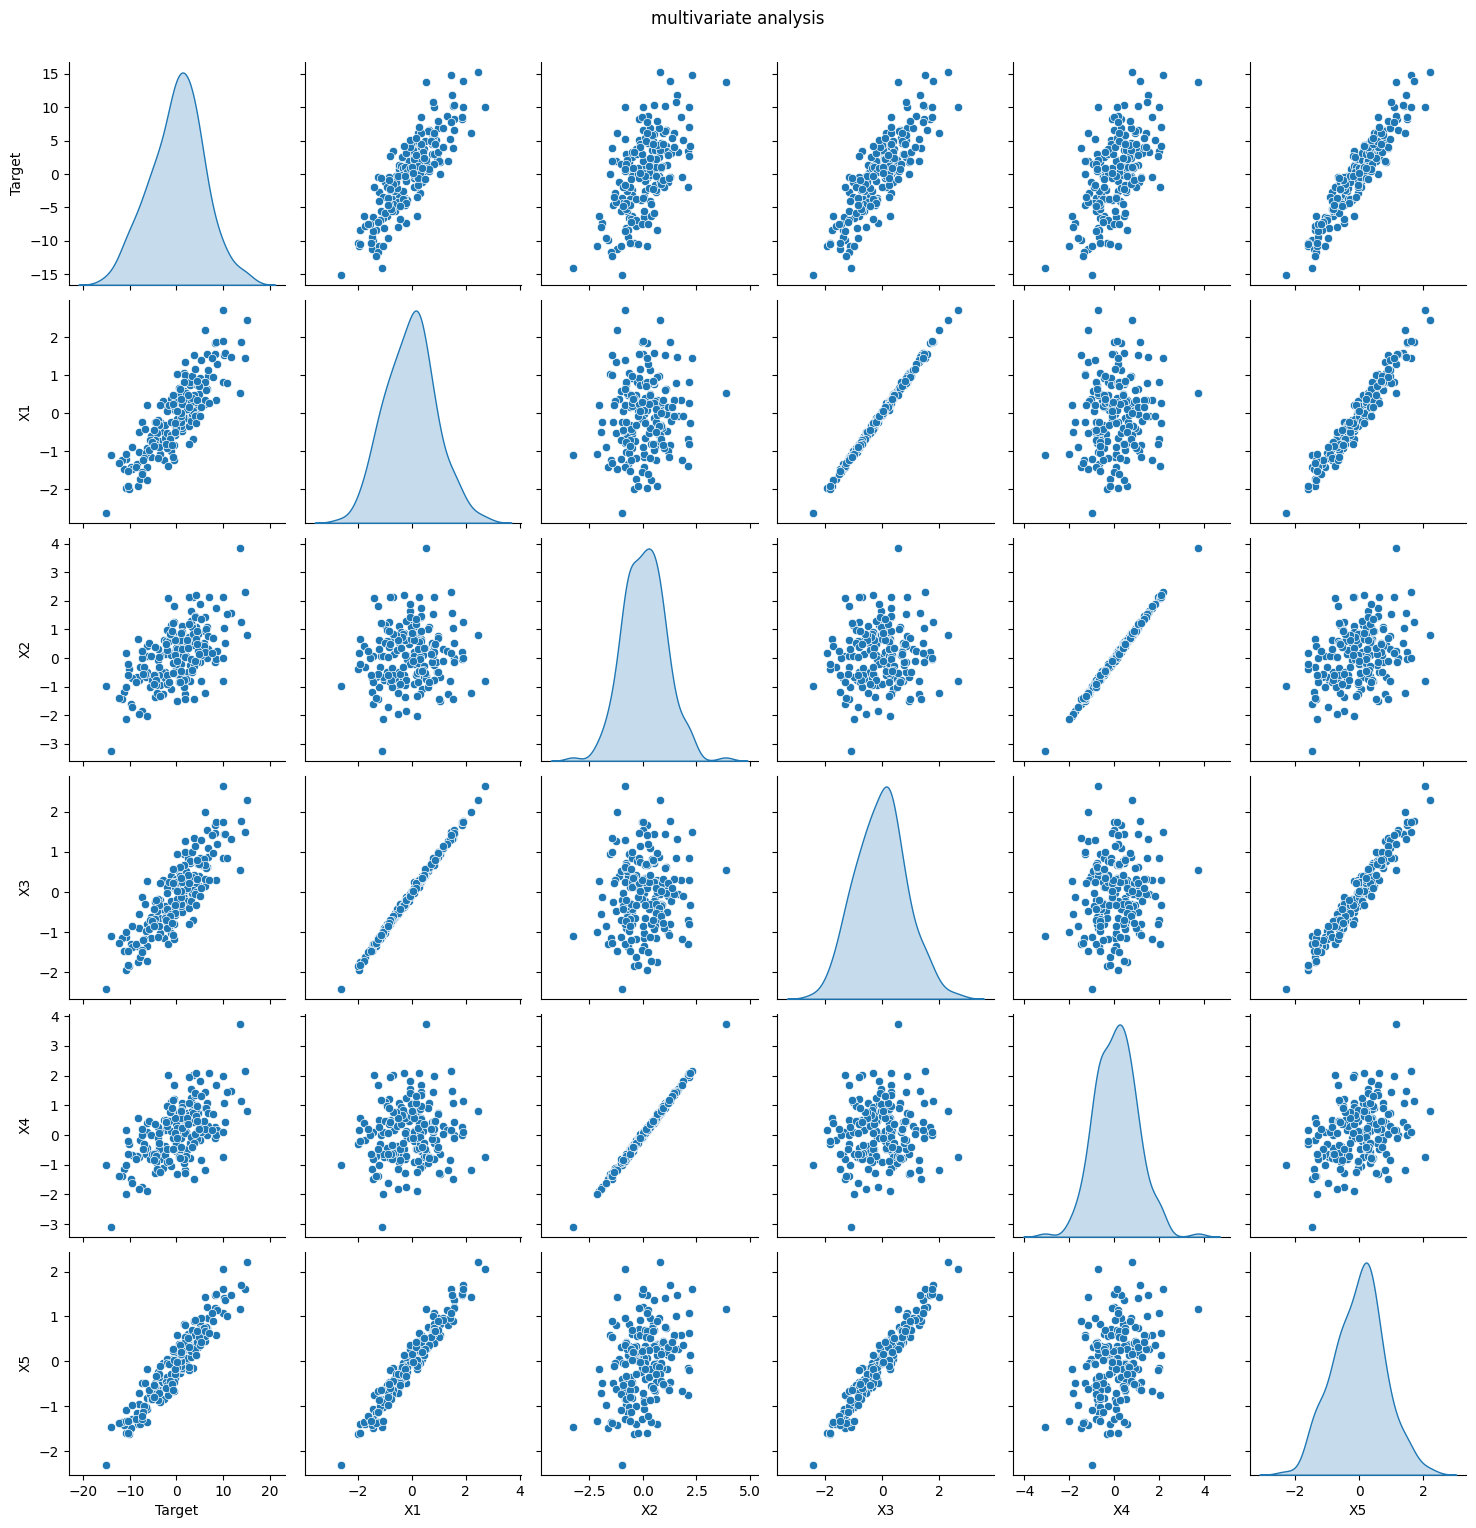

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ["Target","X1","X2","X3","X4","X5"]
multivariate_df = df[cols]
plt.figure(figsize=(8,6))
sns.pairplot(
    multivariate_df ,
    diag_kind = 'kde',
)
plt.suptitle('multivariate analysis' , y = 1.02)
plt.show()

<Axes: >

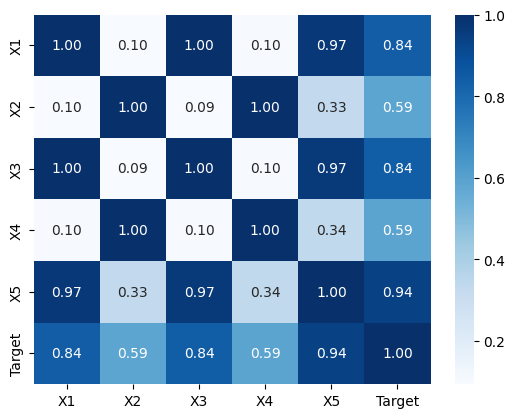

In [34]:
sns.heatmap(
    df.corr(),
    annot=True,
    fmt='.2f',
    cmap='Blues'
)

In [36]:
cols = ["X1","X2","X3","X4","X5"]
x = df[cols]
y = df['Target']

In [37]:
x_train , x_test , y_train , y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

In [38]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.fit_transform(x_test)

In [39]:
linear_model = LinearRegression()
linear_model.fit(x_train,y_train)
linear_predictions = linear_model.predict(x_test)

print(linear_predictions)

[-10.14224781  -1.51604564  -5.72411558  -5.8864956    1.90138643
   1.02456311  -3.23627356  -5.15620089   6.67479246  -5.27432443
   3.54682331 -12.27383468   0.79823353  -0.30302091   3.15724552
   7.18540045  -1.56779594  -2.07488983  11.78665806   0.36180961
   0.04576525  -8.18694012   0.18137794   0.35004981   3.13803252
  -5.85390633   1.30689567   0.71950341   7.68963192  -6.1295921
  12.73210501  -6.82252034   3.05934139   5.36630224   1.6087012
  -1.30484741   7.13783353  -2.98853514   6.24571729   0.33598364]


In [55]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100,200,300,400,500,600,700]

mae_scores , r2_scores = [],[]
for a in alphas :
  ridge = Ridge(alpha = a)
  ridge.fit(x_train,y_train)
  r2_scores.append(r2_score(y_test,ridge.predict(x_test)))
  mae_scores.append(mean_absolute_error(y_test,ridge.predict(x_test)))

results = pd.DataFrame({
    "Alpha" : alphas,
    "r2_score" : r2_scores,
    "mae" : mae_scores
})

results


,Alpha,r2_score,mae
0,0.001,0.945136,1.053703
1,0.010,0.945279,1.052365
2,0.100,0.946222,1.042076
3,1.000,0.947998,1.017018
4,10.000,0.949759,0.997221
5,100.000,0.935752,1.095835
6,200.000,0.890871,1.361043
7,300.000,0.837493,1.651174
8,400.000,0.784245,1.894355
9,500.000,0.734226,2.110853


alpha = 10 seems like a better choice

In [45]:
ridge_model = Ridge(alpha=10)
ridge_model.fit(x_train,y_train)
ridge_predictions = ridge_model.predict(x_test)

print(ridge_predictions)

[ -9.9365546   -1.68319835  -5.998605    -5.84842747   1.81574077
   1.23211169  -3.31411638  -5.06967991   6.70683287  -5.10448733
   3.51416679 -11.86851987   0.62317048   0.41500838   3.01761221
   7.27823526  -1.64269294  -1.9093234   11.1823144    0.0408529
  -0.09875378  -7.73958859   0.23486682   0.11683973   3.11807181
  -5.38144425   0.89561123   1.03453703   7.27677354  -6.04447319
  12.61525301  -6.45484204   2.87611099   5.1201378    1.51270691
  -1.56762862   7.1053793   -2.98595139   6.47083429   0.35768584]


In [46]:
def evaluate_model(name, y_true, y_pred):

    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    print("\n", name)
    print("-" * 30)

    print("MSE  :", mse)
    print("RMSE :", rmse)
    print("MAE  :", mae)
    print("R²   :", r2)

In [47]:
evaluate_model("Multiple Linear Regression", y_test, linear_predictions)
evaluate_model("Ridge Regression",y_test,ridge_predictions)


 Multiple Linear Regression
------------------------------
MSE  : 1.5365111505636135
RMSE : 1.2395608700518155
MAE  : 1.0538567375199277
R²   : 0.9451187022379538

 Ridge Regression
------------------------------
MSE  : 1.406605667572191
RMSE : 1.1860040756979677
MAE  : 0.9972213308777447
R²   : 0.9497586825533323


In [44]:
comparison = pd.DataFrame({
    "Feature": x.columns,
    "Linear Regression": linear_model.coef_,
    "Ridge Regression": ridge_model.coef_
})

print(comparison)

  Feature  Linear Regression  Ridge Regression
0      X1           4.937869          1.387060
1      X2           2.773026          1.122034
2      X3          -2.252739          1.347133
3      X4          -0.356737          1.108651
4      X5           2.040636          1.566730


the coefficients are not that much scaled anymore

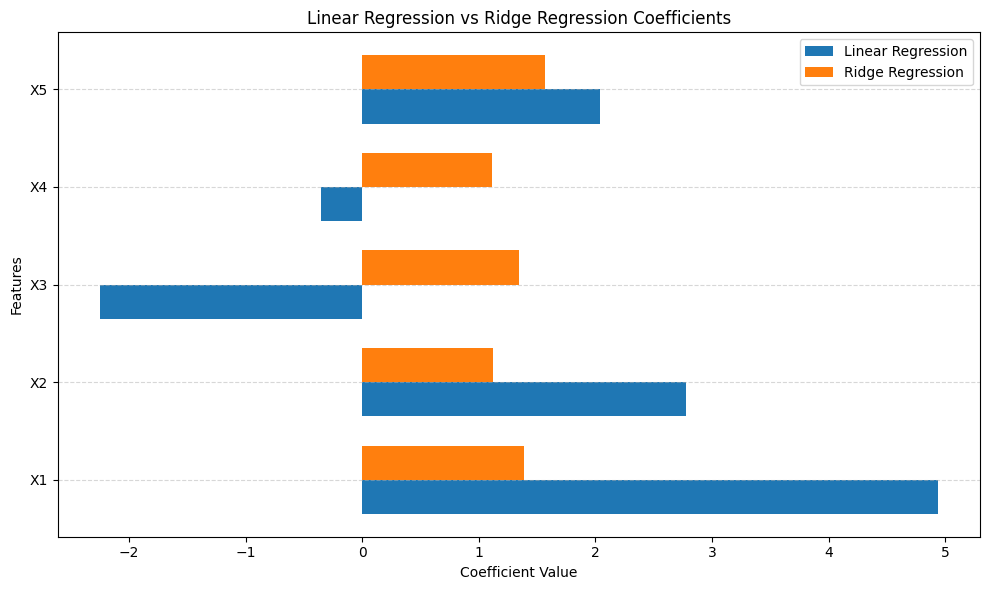

In [66]:
import matplotlib.pyplot as plt
import numpy as np
features = comparison["Feature"]
x = np.arange(len(features))
width = 0.35

plt.figure(figsize=(10, 6))
plt.barh(x - width/2,comparison["Linear Regression"],width,label="Linear Regression")
plt.barh(x + width/2,comparison["Ridge Regression"],width,label="Ridge Regression")
plt.ylabel("Features")
plt.xlabel("Coefficient Value")
plt.title("Linear Regression vs Ridge Regression Coefficients")
plt.yticks(x, features)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()